
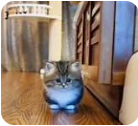

In [70]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yasserh/titanic-dataset")

print("Path to dataset files:", path)




Path to dataset files: C:\Users\Даниил\.cache\kagglehub\datasets\yasserh\titanic-dataset\versions\1


In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
import os

df = pd.read_csv(os.path.join(path, "Titanic-Dataset.csv"))
df = df.drop(columns=["PassengerId"])
df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [72]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    str    
 3   Sex       891 non-null    str    
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    str    
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    str    
 10  Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 76.7 KB


In [73]:
df.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [74]:
df.duplicated().sum()

np.int64(0)

In [75]:
df[df["Age"].isnull()].head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
5,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
17,1,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,NaN,S
19,1,3,"Masselmani, Mrs. Fatima",female,NaN,0,0,2649,7.2250,NaN,C
26,0,3,"Emir, Mr. Farred Chehab",male,NaN,0,0,2631,7.2250,NaN,C
28,1,3,"O'Dwyer, Miss. Ellen ""Nellie""",female,NaN,0,0,330959,7.8792,NaN,Q


In [76]:
df["Age"].mean()

np.float64(29.69911764705882)

In [77]:
df["Age"] = df["Age"].fillna(df["Age"].mean())

In [78]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [79]:
print(df.isnull().sum())

Survived      0
Pclass        0
Name          0
Sex           0
Age           0
SibSp         0
Parch         0
Ticket        0
Fare          0
Cabin       687
Embarked      0
dtype: int64


In [80]:
from sklearn.model_selection import train_test_split


X = df.drop(columns=['Survived'])
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y # учим находить x по y
)


print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).sort_index())
print(y_test.value_counts(normalize=True).sort_index())

(712, 10) (179, 10)
Survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64
Survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


In [81]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score



dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train, y_train)


pred = dummy_clf.predict(X_test)
print(accuracy_score(y_test, pred))
print(precision_score(y_test, pred, zero_division=0))
print(recall_score(y_test, pred))
print(f1_score(y_test, pred))

0.6145251396648045
0.0
0.0
0.0


In [82]:
df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [83]:
df.head()
df["Embarked"].info()
df["Cabin"].value_counts()



<class 'pandas.Series'>
RangeIndex: 891 entries, 0 to 890
Series name: Embarked
Non-Null Count  Dtype
--------------  -----
891 non-null    str  
dtypes: str(1)
memory usage: 7.1 KB


Cabin
G6             4
C23 C25 C27    4
B96 B98        4
F33            3
E101           3
              ..
E17            1
A24            1
C50            1
B42            1
C148           1
Name: count, Length: 147, dtype: int64

In [84]:
from sklearn.model_selection import train_test_split


X = df.drop(columns=['Survived', 'Name', 'Cabin', 'Ticket'])
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})
X["Embarked"] = X["Embarked"].map({"S": 0, "C": 1, "Q": 2})
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y # учим находить x по y
)


print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).sort_index())
print(y_test.value_counts(normalize=True).sort_index())

(712, 7) (179, 7)
Survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64
Survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


0.7988826815642458
0.8113207547169812
0.6231884057971014
0.7049180327868853


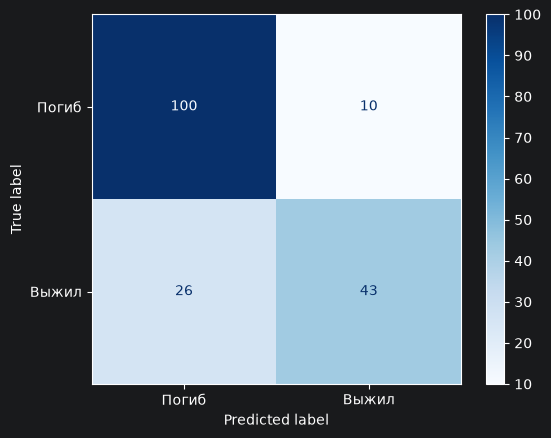

In [113]:

from sklearn.tree import DecisionTreeClassifier


tree_clf = DecisionTreeClassifier(max_depth=6,min_samples_leaf=10, random_state=42)
tree_clf.fit(X_train, y_train)

pred = tree_clf.predict(X_test)
print(accuracy_score(y_test, pred))
print(precision_score(y_test, pred, zero_division=0))
print(recall_score(y_test, pred))
print(f1_score(y_test, pred))

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, pred,
    display_labels=["Погиб", "Выжил"],
    cmap="Blues",
)
plt.show()

0.7988826815642458
0.7796610169491526
0.6666666666666666
0.71875


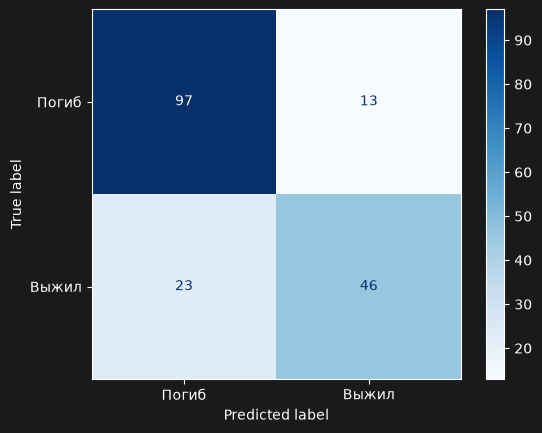

In [86]:

from sklearn.ensemble import RandomForestClassifier


tree_clf = RandomForestClassifier(n_estimators=500,min_samples_leaf=2, random_state=42, n_jobs=1)
tree_clf.fit(X_train, y_train)

pred = tree_clf.predict(X_test)
print(accuracy_score(y_test, pred))
print(precision_score(y_test, pred, zero_division=0))
print(recall_score(y_test, pred))
print(f1_score(y_test, pred))

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, pred,
    display_labels=["Погиб", "Выжил"],
    cmap="Blues",
)
plt.show()

In [87]:
X.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

0.7932960893854749
0.7857142857142857
0.6376811594202898
0.704


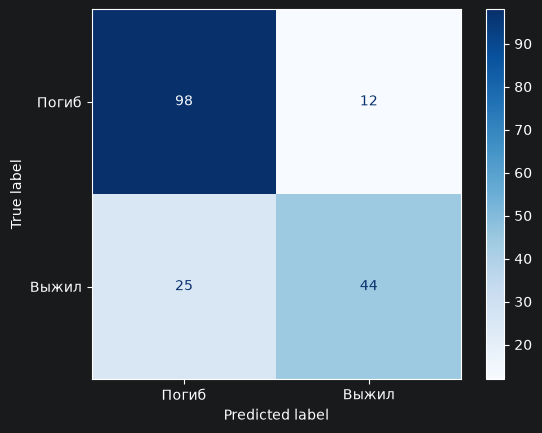

In [108]:

from sklearn.ensemble import GradientBoostingClassifier


tree_clf = GradientBoostingClassifier(n_estimators=200,learning_rate=0.1, max_depth=2, random_state=42)
tree_clf.fit(X_train, y_train)

pred = tree_clf.predict(X_test)
print(accuracy_score(y_test, pred))
print(precision_score(y_test, pred, zero_division=0))
print(recall_score(y_test, pred))
print(f1_score(y_test, pred))

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, pred,
    display_labels=["Погиб", "Выжил"],
    cmap="Blues",
)
plt.show()

In [89]:
X_train.describe().loc[["mean", "std", "min", "max"]]

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
mean,2.308989,0.355337,29.786797,0.492978,0.390449,31.819826,0.349719
std,0.833563,0.478952,13.015124,1.060720,0.838134,48.059104,0.618423
min,1.000000,0.000000,0.420000,0.000000,0.000000,0.000000,0.000000
max,3.000000,1.000000,80.000000,8.000000,6.000000,512.329200,2.000000


In [90]:
a, b = X_train.iloc[0], X_train.iloc[1]
print((a - b) ** 2)

Pclass         1.000000
Sex            0.000000
Age            0.000000
SibSp          0.000000
Parch          0.000000
Fare        3191.775418
Embarked       0.000000
dtype: float64


In [91]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(X_train)
Xs = pd.DataFrame(sc.transform(X_train), columns=X_train.columns)
print((Xs.iloc[0] - Xs.iloc[1]) ** 2)

Pclass      1.441230
Sex         0.000000
Age         0.000000
SibSp       0.000000
Parch       0.000000
Fare        1.383858
Embarked    0.000000
dtype: float64


0.8156424581005587
0.86
0.6231884057971014
0.7226890756302521


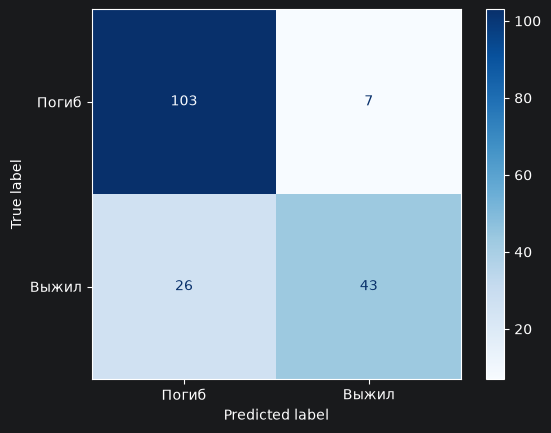

In [92]:
from sklearn.svm import SVC

Xs_test = pd.DataFrame(sc.transform(X_test), columns=X_test.columns)
svm = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
svm.fit(Xs, y_train)


pred = svm.predict(Xs_test)


print(accuracy_score(y_test, pred))
print(precision_score(y_test, pred, zero_division=0))
print(recall_score(y_test, pred))
print(f1_score(y_test, pred))

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, pred,
    display_labels=["Погиб", "Выжил"],
    cmap="Blues",
)
plt.show()

0.8044692737430168
0.7931034482758621
0.6666666666666666
0.7244094488188977


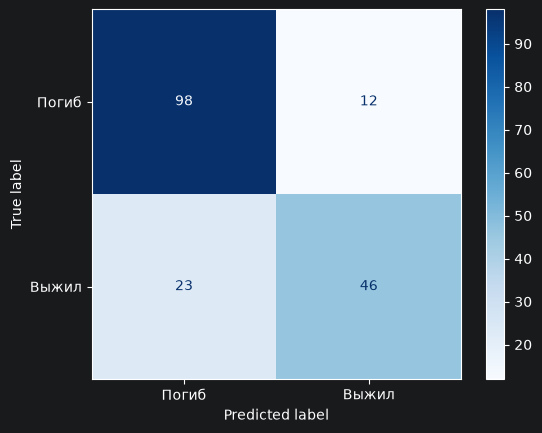

In [93]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=50)
knn.fit(Xs, y_train)
pred = knn.predict(Xs_test)


print(accuracy_score(y_test, pred))
print(precision_score(y_test, pred, zero_division=0))
print(recall_score(y_test, pred))
print(f1_score(y_test, pred))

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, pred,
    display_labels=["Погиб", "Выжил"],
    cmap="Blues",
)
plt.show()

In [115]:
models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=2, random_state=42, n_jobs=1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=2, random_state=42),
    "SVM": SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=50),
}

scaled = ["SVM", "KNN"]  # им нужны масштабированные данные


rows = []

for name, model in models.items():
    if name in scaled:
        model.fit(Xs, y_train)
        pred = model.predict(Xs_test)
    else:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

    rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })


results = pd.DataFrame(rows).set_index("Модель").round(3)



results.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1
Модель,,,,
KNN,0.804,0.793,0.667,0.724
SVM,0.816,0.860,0.623,0.723
Random Forest,0.799,0.780,0.667,0.719
Decision Tree,0.799,0.811,0.623,0.705
Gradient Boosting,0.793,0.786,0.638,0.704
Baseline,0.615,0.000,0.000,0.000


Модели получились очень близкими: разница всего в несколько пассажиров из тестовой выборки, поэтому явного лидера нет. Немного лучше остальных SVM — у него самая высокая accuracy и precision. У всех моделей низкий recall, потому что выживших в данных меньше и модели чаще предсказывают «погиб». Ансамбли деревьев сильнее подстраиваются под обучающую выборку, а KNN с большим k, наоборот, слишком упрощает границу.

In [116]:
dt_clf = DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=42)
rf_clf = RandomForestClassifier(n_estimators=500, min_samples_leaf=2, random_state=42, n_jobs=1)
gb_clf = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=2, random_state=42)

dt_clf.fit(X_train, y_train)
rf_clf.fit(X_train, y_train)
gb_clf.fit(X_train, y_train)


importance = pd.DataFrame({
    "Decision Tree": dt_clf.feature_importances_,
    "Random Forest": rf_clf.feature_importances_,
    "Gradient Boosting": gb_clf.feature_importances_,
}, index=X_train.columns)

importance = importance.sort_values("Random Forest", ascending=False).round(3)
importance

,Decision Tree,Random Forest,Gradient Boosting
Sex,0.547,0.327,0.492
Fare,0.133,0.245,0.151
Age,0.095,0.196,0.147
Pclass,0.186,0.112,0.156
SibSp,0.003,0.048,0.029
Parch,0.001,0.036,0.007
Embarked,0.035,0.036,0.018


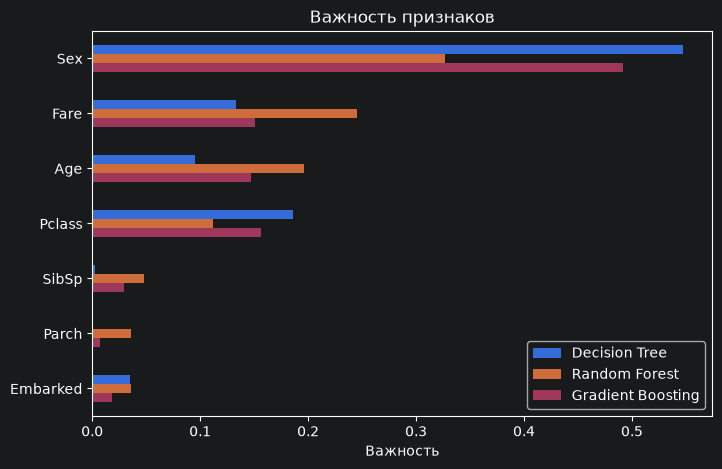

In [117]:
importance.plot.barh(figsize=(8, 5))
plt.gca().invert_yaxis()  # самый важный признак сверху
plt.xlabel("Важность")
plt.title("Важность признаков")
plt.show()

In [122]:
print(df.groupby("Sex")["Survived"].mean())
print(df.groupby("Pclass")["Survived"].mean())

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


Самый важный признак у всех трёх моделей — пол (Sex). Дальше идут класс каюты (Pclass), цена билета (Fare) и возраст (Age). SibSp, Parch и Embarked почти не влияют.

Модели немного расходятся. У Decision Tree и Gradient Boosting пол забирает около половины всей важности. У Random Forest важность распределена ровнее, и Fare с Age поднимаются выше, потому что лес строит много деревьев на случайных подмножествах признаков, а числовые признаки с большим числом значений чаще используются для разбиений.

Это совпадает с первичным анализом: женщины выживали в 74% случаев, мужчины — в 19%; в 1-м классе выжило 63%, в 3-м — 24%.

Важный для модели признак не обязательно является причиной выживания. Важность показывает только, что признак помогает предсказывать, то есть связан с результатом. Например, Fare важен не потому, что цена билета спасала, а потому, что дорогие билеты были у пассажиров 1-го класса, которые были ближе к шлюпкам. Пол важен из-за правила «женщины и дети первыми», а не сам по себе.

In [ ]:
Лучшая - опорные вектора

In [123]:
pred = svm.predict(Xs_test)

errors = df.loc[X_test.index].copy()
errors["pred"] = pred
errors["err"] = errors["pred"] != errors["Survived"]

errors["type"] = "ok"
errors.loc[(errors["Survived"] == 1) & (errors["pred"] == 0), "type"] = "FN"  # выжил, а модель сказала «погиб»
errors.loc[(errors["Survived"] == 0) & (errors["pred"] == 1), "type"] = "FP"  # погиб, а модель сказала «выжил»

errors["type"].value_counts()

type
ok    146
FN     26
FP      7
Name: count, dtype: int64

In [124]:
print(errors.groupby("Sex")["err"].agg(["size", "mean"]))
print(errors.groupby("Pclass")["err"].agg(["size", "mean"]))
print(errors.groupby(["Sex", "Pclass"])["err"].agg(["size", "mean"]))
print(pd.crosstab([errors["Sex"], errors["Pclass"]], errors["type"]))

        size      mean
Sex                   
female    61  0.213115
male     118  0.169492
        size      mean
Pclass                
1         45  0.244444
2         34  0.088235
3        100  0.190000
               size      mean
Sex    Pclass                
female 1         15  0.066667
       2         18  0.055556
       3         28  0.392857
male   1         30  0.333333
       2         16  0.125000
       3         72  0.111111
type           FN  FP  ok
Sex    Pclass            
female 1        0   1  14
       2        0   1  17
       3        7   4  17
male   1        9   1  20
       2        2   0  14
       3        8   0  64


In [125]:
errors[errors["err"]][["Name", "Sex", "Age", "Pclass", "SibSp", "Parch", "Fare", "Survived", "pred", "type"]]

,Name,Sex,Age,Pclass,SibSp,Parch,Fare,Survived,pred,type
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.000000,3,0,0,7.2250,1,0,FN
559,"de Messemaeker, Mrs. Guillaume Joseph (Emma)",female,36.000000,3,1,0,17.4000,1,0,FN
216,"Honkanen, Miss. Eliina",female,27.000000,3,0,0,7.9250,1,0,FN
27,"Fortune, Mr. Charles Alexander",male,19.000000,1,3,2,263.0000,0,1,FP
279,"Abbott, Mrs. Stanton (Rosa Hunt)",female,35.000000,3,1,1,20.2500,1,0,FN
712,"Taylor, Mr. Elmer Zebley",male,48.000000,1,1,0,52.0000,1,0,FN
455,"Jalsevac, Mr. Ivan",male,29.000000,3,0,0,7.8958,1,0,FN
65,"Moubarek, Master. Gerios",male,29.699118,3,1,1,15.2458,1,0,FN
489,"Coutts, Master. Eden Leslie ""Neville""",male,9.000000,3,1,1,15.9000,1,0,FN
297,"Allison, Miss. Helen Loraine",female,2.000000,1,1,2,151.5500,0,1,FP


In [128]:
for col in [None, "Fare", "Sex"]:
    if col is None:
        a, b = X_train, X_test
    else:
        a, b = X_train.drop(columns=[col]), X_test.drop(columns=[col])

    sc2 = StandardScaler().fit(a)
    m = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
    m.fit(sc2.transform(a), y_train)

    print("без", col, f1_score(y_test, m.predict(sc2.transform(b))))

без None 0.7226890756302521
без Fare 0.717948717948718
без Sex 0.5084745762711864


Модель ошиблась 33 раза из 179: 26 раз сказала «погиб» про выжившего (FN) и только 7 раз наоборот (FP). Она склоняется к классу «погиб», которого в данных больше.

Чаще всего модель ошибается на женщинах 3-го класса (39% ошибок) и мужчинах 1-го класса (33%). В этих группах не работает простое правило «женщины выживают, мужчины нет».

Примеры:  богатый молодой мужчина Fortune погиб, а модель решила, что он выживет.

Утечки нет: PassengerId, Name, Ticket и Cabin не используются. Без Fare F1 почти не меняется (0.723 → 0.718), а без Sex падает до 0.508, значит, модель опирается на реальную закономерность.